# Tomografía de primeras llegadas: inversión de rayos rectos retenidos

**Pregunta:** ¿La inversión de lentitud por rayos rectos predice profundidades de fuente retenidas dentro de la escala de ruido asumida?
**Nivel 2 — Métodos inversos aplicados** · 60–75 min · álgebra lineal y mínimos cuadrados

## Objetivos
Construir una matriz de longitudes de rayo para llegadas crosshole sintéticas; resolver una inversa 2D regularizada de lentitud con fuentes de entrenamiento; comparar baseline homogéneo e inversa en profundidades completas retenidas; inspeccionar cobertura y no unicidad.

## Preparación

Ejecute desde la raíz en el entorno fijado:
pip install numpy==2.2.6 scipy==1.15.2 matplotlib==3.10.8

La celda experimental imprime las versiones activas.

## Datos
Todas las llegadas se generan determinísticamente en memoria. Son datos crosshole sintéticos, no del levantamiento Koenigsee. data-pipeline/traveltime.py implementa aparte parseo/QC estricto .sgt e inversión pyGIMLi condicional; los bytes de fuente no están incluidos, por lo que este capítulo no fabrica ni sustituye observaciones de terreno.

## Método

Para trayectoria fija Γᵢ, el tiempo de primera llegada es tᵢ=∫Γᵢ s(x,z)dl, con lentitud s=1/v en s/m. Al discretizar celdas se obtiene t≈A s; Aᵢⱼ es la longitud en metros del rayo i dentro de la celda j. Es lineal en lentitud solo con geometría recta fija. Omite curvatura, topología de refracción, anisotropía y efectos de frecuencia finita.

Estimamos lentitud homogénea s₀ con entrenamiento únicamente y resolvemos q=(s−s₀)/(1/3000 s/m), adimensional, minimizando ||W(A s₀ + A s_scale q − t)||² + λ||Dq||². W=1/σt y D es un operador de diferencias primeras entre vecinas. Se retienen profundidades completas de fuente; los tiempos retenidos no definen s₀, inversión, λ ni selección del modelo. RMSE/WRMS retenidos son diagnósticos posteriores.

M09 del producto en data-pipeline/traveltime.py valida geometría y picks .sgt atribuidos, conserva banderas de anomalía, crea particiones por disparo completo y ejecuta inversión no lineal pyGIMLi en malla congelada. Sus datos de terreno no están incluidos. Este notebook es un complemento lineal sintético, no un replay ni proxy de aquella ruta.

### Preguntas
1. ¿Dónde escasean conteos o ángulos de rayo y qué celdas son menos identificables?
2. ¿La inversa mejora error retenido frente al baseline homogéneo?
3. ¿Qué cambia al curvar rayos y reconstruir iterativamente la matriz?

### Interpretación de la prueba retenida

El modelo directo es lineal en lentitud solo después de fijar geometría de trayectorias. Cada fila de la matriz de longitudes representa un segmento recto a través de celdas. El tiempo observado suma longitud por lentitud, mientras que velocidad entra mediante su recíproco. El notebook estima una lentitud base y resuelve perturbaciones escaladas; la regularización actúa sobre diferencias entre celdas vecinas. Esto hace manejable el objetivo, pero no vuelve válida la aproximación de rayos rectos en medios fuertemente refractivos.

La partición retiene profundidades de fuente completas, así las filas de entrenamiento y prueba no comparten el mismo punto fuente. Coordenadas y verdad sintética son conocidas por ser un experimento controlado. El flujo de campo valida bytes originales, identidad de sensores y particiones por fuente antes de invertir con pyGIMLi. Responden preguntas distintas y no deben describirse como un único resultado reproducido.

La normalización WRMS usa la desviación estándar de tiempo asumida. Un valor cercano a uno es consistente con el ruido declarado; 5.591 indica discrepancias retenidas sustancialmente mayores. RMSE contra verdad solo existe porque el ejemplo es sintético. Ayuda a diagnosticar esta inversión, pero no se calcula para un modelo de campo desconocido. Suavidad, cobertura y semejanza visual no reemplazan análisis de resolución o incertidumbre.

### Experimento 2 — varíe ruido y suavidad, luego ajuste

Cambie RAY_NOISE_S y LAMBDA_SMOOTH. Una semilla fija reproduce el ruido agregado a picks. Retenga profundidades completas de fuente, no filas aleatorias de rayos.

In [1]:
from importlib.metadata import version

print("Versiones del entorno:", {name: version(name) for name in ["numpy", "scipy", "matplotlib"]})
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix, vstack
from scipy.sparse.linalg import lsqr

# Levantamiento crosshole sintético: pozos verticales; coordenadas en metros.
nx, nz = 12, 6
dx = dz = 500.0
x_edges = np.arange(nx + 1) * dx
z_edges = np.arange(nz + 1) * dz
x_src = np.zeros(12)
z_src = (np.arange(12) + 0.5) * 250.0
x_rec = np.full(12, nx * dx)
z_rec = (np.arange(12) + 0.5) * 250.0
# Verdad sintética conocida; nunca se entrega a la inversa.
velocity_true = np.full((nz, nx), 2600.0)
velocity_true[2:, :] = 3600.0
velocity_true[1:5, 5:8] = 2050.0
slowness_true = 1.0 / velocity_true
src_ids, rec_ids = np.meshgrid(np.arange(12), np.arange(12), indexing="ij")
src_ids, rec_ids = src_ids.ravel(), rec_ids.ravel()
n_rays = len(src_ids)
rows, cols, lengths = [], [], []


Versiones del entorno: {'numpy': '2.2.6', 'scipy': '1.15.2', 'matplotlib': '3.10.8'}


### Cada segmento fuente-receptor se muestrea a través de la malla y se acumula en una matriz dispersa de longitudes de trayectoria. La entrada Aᵢⱼ aproxima los metros recorridos por el rayo i en la celda j, de modo que t=A s para trayectorias rectas fijas. Los 5.000 puntos controlan el error de discretización; esta geometría omite la refracción y no debe confundirse con la inversión de campo del producto con pyGIMLi.

In [2]:
for i, (si, ri) in enumerate(zip(src_ids, rec_ids)):
    x0, z0, x1, z1 = x_src[si], z_src[si], x_rec[ri], z_rec[ri]
    distance = np.hypot(x1 - x0, z1 - z0)
    n_sample = 5000
    u = (np.arange(n_sample) + 0.5) / n_sample
    xs = x0 + u * (x1 - x0)
    zs = z0 + u * (z1 - z0)
    ix = np.clip(np.searchsorted(x_edges, xs, side="right") - 1, 0, nx - 1)
    iz = np.clip(np.searchsorted(z_edges, zs, side="right") - 1, 0, nz - 1)
    cells, counts = np.unique(iz * nx + ix, return_counts=True)
    rows.extend([i] * len(cells))
    cols.extend(cells.tolist())
    lengths.extend((counts * distance / n_sample).tolist())
A = csr_matrix((lengths, (rows, cols)), shape=(n_rays, nx * nz))
RAY_NOISE_S = 0.0005
SEED = 60427
sigma_t = RAY_NOISE_S
rng = np.random.default_rng(SEED)
t_obs = A @ slowness_true.ravel() + rng.normal(0, sigma_t, n_rays)
# Se retienen profundidades completas de fuente; política fijada antes de examinar tiempos.
held_sources = np.array([1, 4, 7, 10])
held = np.isin(src_ids, held_sources)
train = ~held
assert train.any() and held.any()


### La lentitud base s₀ es la constante de mínimos cuadrados calculada solo con las llegadas de entrenamiento. Las profundidades completas de las fuentes definen la máscara de prueba antes de invertir y evitan compartir fuentes entre particiones. Escalar la perturbación de lentitud por 1/3000 s/m vuelve adimensional la actualización del modelo; esta escala cambia el condicionamiento, no los datos ni las trayectorias asumidas.

In [3]:
# Ajusta la velocidad homogénea de referencia usando solo rayos de entrenamiento.
distance = np.asarray(A.sum(axis=1)).ravel()
s0 = float(np.dot(distance[train], t_obs[train]) / np.dot(distance[train], distance[train]))
scale_s = 1 / 3000.0
Atr = A[train]
G = Atr * scale_s / sigma_t
rhs = (t_obs[train] - Atr @ np.full(nx * nz, s0)) / sigma_t
pairs = []
for iz in range(nz):
    for ix in range(nx):
        j = iz * nx + ix
        if ix + 1 < nx:
            pairs.append((j, j + 1))
        if iz + 1 < nz:
            pairs.append((j, j + nx))
rr = []
cc = []
vv = []
for k, (a, b) in enumerate(pairs):
    rr.extend([k, k])
    cc.extend([a, b])
    vv.extend([-1.0, 1.0])
D = csr_matrix((vv, (rr, cc)), shape=(len(pairs), nx * nz))
LAMBDA_SMOOTH = 0.45


### LSQR resuelve el sistema disperso ponderado después de añadir el operador de primeras diferencias. Sus filas penalizan los cambios de lentitud entre celdas vecinas, y λ controla el equilibrio entre ajuste a datos y suavidad. Inspeccione la velocidad recuperada junto con la cobertura de trayectorias: una solución estable en celdas poco muestreadas sigue dominada por el prior y no demuestra resolución.

In [4]:
# Resuelve la actualización regularizada de lentitud con los residuales seleccionados.
system = vstack([G, np.sqrt(LAMBDA_SMOOTH) * D], format="csr")
q = lsqr(system, np.r_[rhs, np.zeros(D.shape[0])], atol=1e-10, btol=1e-10, iter_lim=400)[0]
slowness_est = s0 + scale_s * q
velocity_est = 1 / slowness_est.reshape(nz, nx)
pred = np.asarray(A @ slowness_est).ravel()
base = distance * s0


def score(prediction, mask):
    residual = prediction[mask] - t_obs[mask]
    return {
        "n": int(mask.sum()),
        "RMSE_ms": float(np.sqrt(np.mean(residual**2)) * 1000),
        "WRMS": float(np.sqrt(np.mean((residual / sigma_t) ** 2))),
    }


### La tabla evalúa ambos modelos con los mismos rayos de entrenamiento y de prueba. La mejora en entrenamiento mide el ajuste, mientras que el RMSE de prueba evalúa la predicción en profundidades de fuente no observadas; WRMS divide los residuales por la desviación estándar supuesta del error de llegada. Un valor menor solo es significativo bajo este modelo sintético de ruido y esta política de partición.

In [5]:
# Compara modelos homogéneo y recuperado con los mismos rayos de ajuste y reserva.
table = pd.DataFrame(
    [
        {
            'model': "homogéneo, solo entrenamiento",
            **score(base, train),
            **{f"heldout_{k}": v for k, v in score(base, held).items()},
        },
        {
            'model': "lentitud lineal + suavidad",
            **score(pred, train),
            **{f"heldout_{k}": v for k, v in score(pred, held).items()},
        },
    ]
)
display(table.round(3))


,model,n,RMSE_ms,WRMS,heldout_n,heldout_RMSE_ms,heldout_WRMS
0,"homogéneo, solo entrenamiento",96,178.725,357.450,48,173.868,347.736
1,lentitud lineal + suavidad,96,0.279,0.558,48,2.796,5.591


### Use WRMS=1 en prueba como objetivo nominal de consistencia con el ruido. Un valor mayor significa que el residual supera la escala de error de llegada asumida, aunque mejore frente al modelo homogéneo; un valor menor en rayos sintéticos no valida datos de campo. Al juzgar si esta inversión recuperó estructura útil, conserve el número de rayos, las fuentes retenidas y el error de velocidad informado.

In [6]:
# Resume conteos de rayos, identidad de partición y errores de reserva.
print(
    {
        "rayos": n_rays,
        "entrenamiento": int(train.sum()),
        "retenidos": int(held.sum()),
        "índices_fuente_retenidos": held_sources.tolist(),
        "velocidad_baseline_m_s": 1 / s0,
        "lambda": LAMBDA_SMOOTH,
        "sigma_ruido_ms": sigma_t * 1000,
        "solver": "SciPy LSQR on weighted ray lengths with first-difference penalty",
    }
)

heldout_wrms = score(pred, held)["WRMS"]
print("WRMS retenido:", round(heldout_wrms, 3), "frente al objetivo de ruido unitario 1.0.")
if heldout_wrms > 1:
    print(
        ("El residual excede la escala de ruido supuesta: el ajuste predictivo no es "
         "consistente con ese ruido, aunque mejore frente al baseline.")
    )
else:
    print(
        ("El residual queda dentro de la escala de ruido supuesta para esta partición "
         "sintética; no valida datos de terreno.")
    )

import sys


{'rayos': 144, 'entrenamiento': 96, 'retenidos': 48, 'índices_fuente_retenidos': [1, 4, 7, 10], 'velocidad_baseline_m_s': 2859.842394276743, 'lambda': 0.45, 'sigma_ruido_ms': 0.5, 'solver': 'SciPy LSQR on weighted ray lengths with first-difference penalty'}
WRMS retenido: 5.591 frente al objetivo de ruido unitario 1.0.
El residual excede la escala de ruido supuesta: el ajuste predictivo no es consistente con ese ruido, aunque mejore frente al baseline.


### La ruta del producto localiza el parser estricto del sondeo y el módulo de control de calidad para compararlos con este cálculo controlado. El contrato de entrada de campo conserva identidad de fuente, llegadas, geometría y banderas de anomalía antes de cualquier inversión no lineal. Cargar ese módulo no convierte los arreglos sintéticos anteriores en observaciones de campo ni significa que se haya procesado el sondeo ausente.

In [7]:
# Ejecuta el oráculo pyGIMLi aislado sobre el control sintético FWI declarado.
from pathlib import Path

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))


### Diagnóstico 2 — compare modelo, cobertura y puntajes retenidos

El panel de cobertura cuenta longitud total de trayectorias por celda; no es matriz de resolución. Alta cobertura no demuestra información angular independiente ni recuperación única.

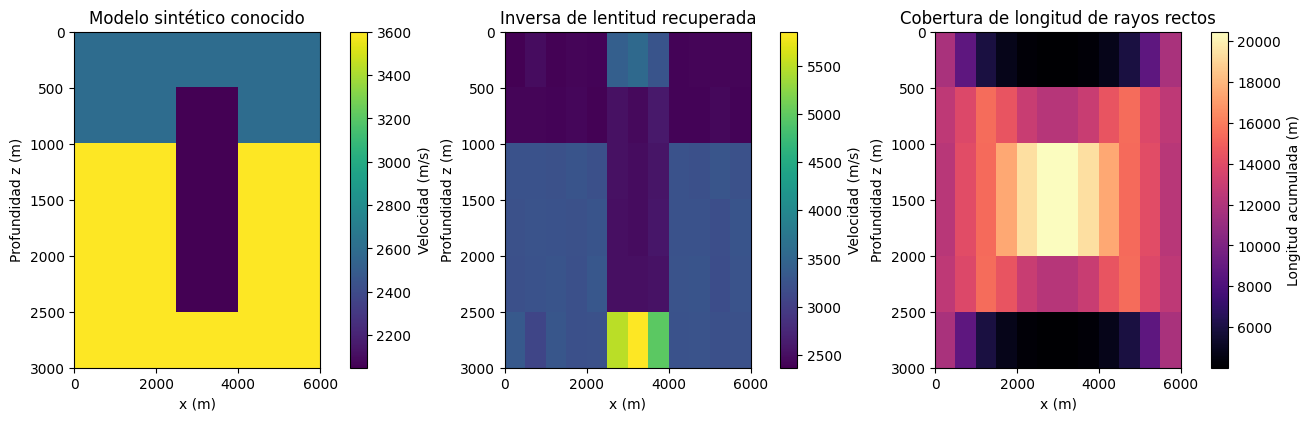

RMSE de velocidad frente a verdad sintética: 534.2767919227546 m/s
Las llegadas retenidas no seleccionaron lambda ni el modelo.


In [8]:
# Celda de experimento reproducible del notebook.
coverage = np.asarray(A.T @ np.ones(n_rays)).reshape(nz, nx)
fig, axes = plt.subplots(1, 3, figsize=(13, 4.1), constrained_layout=True)
extent = [0, nx * dx, nz * dz, 0]
for ax, model, title in zip(
    axes[:2], [velocity_true, velocity_est], ["Modelo sintético conocido", "Inversa de lentitud recuperada"]
):
    im = ax.imshow(model, extent=extent, aspect="auto", cmap="viridis")
    ax.set(title=title, xlabel="x (m)", ylabel="Profundidad z (m)")
    fig.colorbar(im, ax=ax, label="Velocidad (m/s)")
im = axes[2].imshow(coverage, extent=extent, aspect="auto", cmap="magma")
axes[2].set(title="Cobertura de longitud de rayos rectos", xlabel="x (m)", ylabel="Profundidad z (m)")
fig.colorbar(im, ax=axes[2], label="Longitud acumulada (m)")
plt.show()
print(
    "RMSE de velocidad frente a verdad sintética:",
    float(np.sqrt(np.mean((velocity_est - velocity_true) ** 2))),
    "m/s",
)
print("Las llegadas retenidas no seleccionaron lambda ni el modelo.")


### Interpretación de figura

Los paneles comparan velocidad sintética conocida con la estimación de rayos rectos; el tercero muestra longitud acumulada, no resolución posterior. El error frente a la verdad es 534.277 m/s y WRMS retenido es 5.591, mayor que el objetivo unitario. El modelo suave no predice estas llegadas dentro del ruido supuesto, aunque la inversión sea ejecutable.

In [9]:
# Ejecute el método nombrado del pipeline con la entrada declarada en la lección.
from pathlib import Path
import sys

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
from traveltime import Survey, qc, offsets_m

sensor_xy_product = np.vstack([np.c_[x_src, z_src], np.c_[x_rec, z_rec]])
pair_product = np.c_[src_ids, rec_ids + len(x_src)]
survey_product = Survey(sensor_xy_product, pair_product, t_obs)
qc_product = qc(survey_product)
print("cantidad de llegadas y rango de offsets", qc_product["pick_count"], qc_product["offset_range_m"])


cantidad de llegadas y rango de offsets 144 [6000.0, 6600.189391222043]


### Lectura estricta de bytes SGT

El parser del producto recibe bytes UTF-8 originales y exige la gramática declarada de sensores y llegadas antes del control QC. Este paso construye en memoria una línea sintética de 15 sensores y velocidad constante; sirve para enseñar el parser, no son datos de Koenigsee ni evidencia de una inversión de campo.


In [10]:
# Prueba el parser con una línea sintética explícita, no con bytes de campo.
import traveltime

parser_x = np.arange(15, dtype=float) * 400.0
parser_xy = np.column_stack((parser_x, np.zeros_like(parser_x)))
parser_pairs = [(shot, receiver) for shot in range(15) for receiver in range(shot + 1, 15)]
parser_lines = [f"{len(parser_xy)} # shot/geophone points", "#x y"]
for x_value, z_value in parser_xy:
    parser_lines.append(f"{x_value:.3f} {z_value:.3f}")
parser_lines.extend([f"{len(parser_pairs)} # measurements", "#s g t"])
for shot, receiver in parser_pairs:
    distance_m = parser_x[receiver] - parser_x[shot]
    time_s = distance_m / 3000.0
    parser_lines.append(f"{shot + 1} {receiver + 1} {time_s:.9f}")
synthetic_sgt = "\n".join(parser_lines).encode("utf-8")
parsed_survey = traveltime.parse_sgt_bytes(synthetic_sgt)
parsed_qc = traveltime.qc(parsed_survey)
print("Sensores y llegadas SGT sintéticos interpretados", parsed_qc["sensor_count"], parsed_qc["pick_count"])
print("rango de offsets y velocidades aparentes", parsed_qc["offset_range_m"], parsed_qc["apparent_speed_range_m_s"])


Sensores y llegadas SGT sintéticos interpretados 15 105
rango de offsets y velocidades aparentes [400.0, 5600.0] [2999.9999962499996, 3000.0000075000003]


### Partición por fuente

Esta celda ejecuta una operación pública del flujo sobre las entradas declaradas.   


In [11]:
# Ejecute el método nombrado del pipeline con la entrada declarada en la lección.
from pathlib import Path
import sys

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
from traveltime import shot_splits

split_product = shot_splits(survey_product, policy="supplied-whole-shot/v1")
print("grupos retenidos", {key: len(value["held_rows"]) for key, value in split_product.items()})


grupos retenidos {'interleaved': 36, 'central_block': 36}


### Modelo directo homogéneo

Esta celda ejecuta una operación pública del flujo sobre las entradas declaradas.   


In [12]:
# Ejecute el método nombrado del pipeline con la entrada declarada en la lección.
from pathlib import Path
import sys

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
from traveltime import homogeneous_times

homogeneous_product = homogeneous_times(survey_product, 3000.0)
print("Primeros tiempos predichos (s)", homogeneous_product[:3])


Primeros tiempos predichos (s) [2.         2.00173536 2.00693243]


### Sensibilidad de velocidad con una segunda solución directa

La primera llamada del producto predice llegadas a 3000 m/s. Este paso recalcula el mismo levantamiento a 2500 m/s y evalúa ambas líneas base en la reserva intercalada de disparos completos. La comparación aísla cómo la velocidad homogénea supuesta cambia los tiempos retenidos; no cambia geometría de rayos ni afirma una inversión heterogénea.


In [13]:
# Recalcule el mismo sondeo con una velocidad homogénea menor.
from traveltime import homogeneous_times

slow_homogeneous_product = homogeneous_times(survey_product, 2500.0)
held_interleaved = split_product["interleaved"]["held_rows"]
reference_residual = homogeneous_product[held_interleaved] - survey_product.time_s[held_interleaved]
slow_residual = slow_homogeneous_product[held_interleaved] - survey_product.time_s[held_interleaved]
reference_rmse_s = float(np.sqrt(np.mean(reference_residual**2)))
slow_rmse_s = float(np.sqrt(np.mean(slow_residual**2)))
print("RMSE retenido (s) para 3000 y 2500 m/s", reference_rmse_s, slow_rmse_s)


RMSE retenido (s) para 3000 y 2500 m/s 0.1989511533459944 0.3965176698856982


### Diagnóstico de offset

Esta celda ejecuta una operación pública del flujo sobre las entradas declaradas.   


In [14]:
# Ejecute el método nombrado del pipeline con la entrada declarada en la lección.
from pathlib import Path
import sys

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
offset_product = offsets_m(survey_product)
print("Desplazamiento medio y máximo (m)", float(offset_product.mean()), float(offset_product.max()))


Desplazamiento medio y máximo (m) 6121.246206138447 6600.189391222043


### Oráculo de política

Esta celda ejecuta una operación pública del flujo sobre las entradas declaradas.   


In [15]:
import os
# Ejecute el oráculo de políticas del producto en el intérprete aislado de pyGIMLi.
import json
import subprocess

engine_root = Path(os.environ.get("CAOS_SOURCE_ROOT", root))
engine = engine_root / ".venv-ert" / "Scripts" / "python.exe"
if not engine.is_file():
    raise RuntimeError("Este oráculo requiere el entorno aislado de pyGIMLi.")
child = "\n".join(
    [
        "import json, sys",
        "from pathlib import Path",
        "sys.path.insert(0, str(Path(sys.argv[1]) / 'data-pipeline'))",
        "import traveltime",
        "print(json.dumps(traveltime.homogeneous_oracle()))",
    ]
)
completed = subprocess.run(
    [str(engine), "-c", child, str(root)], cwd=root, capture_output=True, text=True, timeout=180
)
if completed.returncode:
    raise RuntimeError(completed.stderr[-2000:])
policy_product = json.loads(completed.stdout.strip().splitlines()[-1])
print("Errores del oráculo", policy_product)


Errores del oráculo {'max_relative_error': 6.938893903907228e-16, 'max_speed_scaling_relative_error': 0.0, 'reciprocity_relative_error': 0.0, 'analytic_basis': 'straight Euclidean path in a homogeneous isotropic medium, t=distance/v'}


### Experimento 3 — ejecute la inversa M09 del producto en un sondeo refractivo sintético

El ejercicio LSQR anterior fija las trayectorias rectas. Este control genera primeras llegadas con Dijkstra de pyGIMLi a través de un modelo de velocidad de dos capas conocido y llama a la misma rutina M09 `_invert_once` que usa el flujo de datos de campo. Retiene grupos completos de fuentes antes de invertir, calcula la referencia homogénea solo con entrenamiento y evalúa el modelo congelado en fuentes no usadas. La verdad sintética se conoce solo porque esta celda la genera; es un control numérico del método, no datos del proveedor, validación de campo ni interpretación geológica.

La ejecución adicional con pyGIMLi utiliza el núcleo inverso M09 del producto en un sondeo refractivo de dos capas generado aquí y evalúa un grupo completo de fuentes retenidas frente a una referencia homogénea. Compare el modelo recuperado con la verdad generada y observe dónde el entrenamiento aporta cobertura de longitud de trayectoria. El resultado demuestra solo el operador y la evaluación retenida; no valida los datos de campo enlazados de Koenigsee, no calibra su incertidumbre, no establece unicidad geológica ni cambia el veredicto del método de campo.

Inversa sintética M09 Dijkstra del producto {'source_kind': 'authored synthetic; no provider bytes', 'shot_count': 15, 'pick_count': 210, 'held_shot_count': 3, 'held_pick_count': 42, 'heldout_rmse_ms': 0.48, 'homogeneous_baseline_heldout_rmse_ms': 3.17712, 'heldout_improvement_fraction': 0.85, 'chi2_assumed_weights': 0.7, 'iterations': 3, 'stopping_reason': 'assumed-chi2-target', 'coverage_nonzero_cell_fraction': 0.4, 'velocity_truth_rmse_m_s': 400}


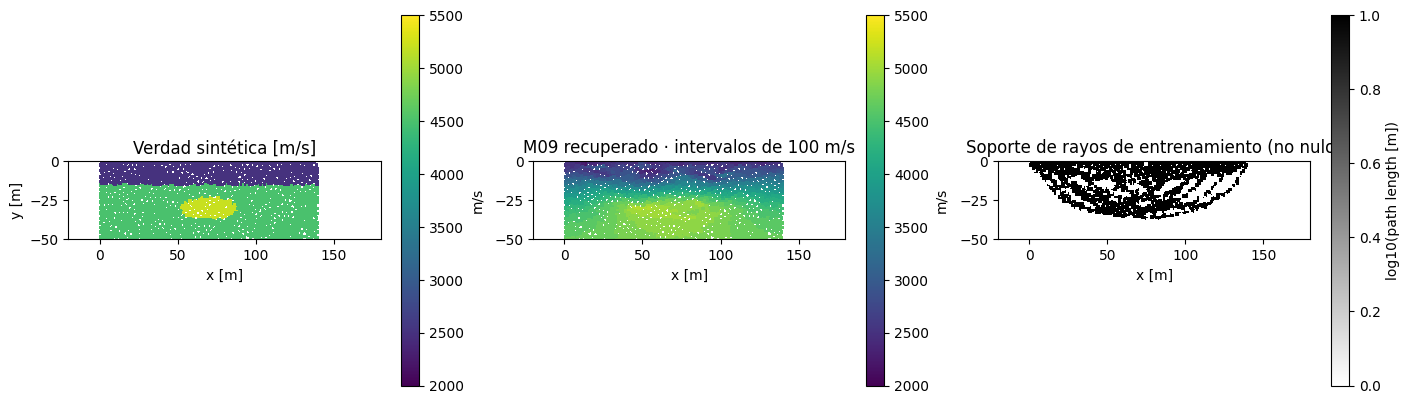

In [16]:
# Genere un sondeo refractivo sintético y ejecute el núcleo inverso M09 exacto en el entorno fijado del solver.
import json, os, subprocess
from pathlib import Path

engine_root = Path(os.environ.get("CAOS_SOURCE_ROOT", root))
engine = next((candidate for candidate in (engine_root / ".venv-ert" / "Scripts" / "python.exe", engine_root / ".venv-ert" / "bin" / "python") if candidate.is_file()), None)
if engine is None:
    raise RuntimeError("The isolated pinned M09 pyGIMLi environment is required for this product-inverse control.")
control_path = Path(os.environ["CAOS_TEMP_ROOT"]) / "m09-product-synthetic-inverse.json"
child = r"""
import json, sys
from pathlib import Path
sys.path.insert(0, str(Path(sys.argv[1]) / "data-pipeline"))
import numpy as np
np.random.seed(20261027)
import pygimli as pg
from pygimli.physics import traveltime as tt
import traveltime as product
pg.utils.noCache(True)
pg.setThreadCount(1)
x = np.arange(15, dtype=float) * 10.0
sensors = np.column_stack([x, np.zeros_like(x)])
pairs = np.asarray([(shot, receiver) for shot in range(15) for receiver in range(15) if shot != receiver], dtype=int)
scheme = tt.DataContainerTT()
for point in sensors:
    scheme.createSensor(point)
scheme.resize(len(pairs))
scheme["s"], scheme["g"] = pairs[:, 0], pairs[:, 1]
truth_mesh = pg.meshtools.createGrid(x=np.arange(-20, 181, 5.0), y=np.arange(-50, 1, 2.5))
truth_centers = np.asarray([[cell.center().x(), cell.center().y()] for cell in truth_mesh.cells()])
truth_velocity = np.where(truth_centers[:, 1] < -15, 4500.0, 2500.0)
body = ((truth_centers[:, 0] - 70) / 18) ** 2 + ((truth_centers[:, 1] + 30) / 7) ** 2 < 1
truth_velocity[body] = 5200.0
arrivals = np.asarray(tt.TravelTimeManager().simulate(mesh=truth_mesh, scheme=scheme, vel=truth_velocity, secNodes=3, returnArray=True), dtype=float)
scheme["t"] = arrivals
survey = product.Survey(sensors, pairs, arrivals)
splits = product.shot_splits(survey, policy="supplied-whole-shot/v1")
fit = product._invert_once(tt, scheme, survey, splits["interleaved"], product.INVERSE_OPTIONS, retain_arrays=True)
centers = np.asarray(fit["model_cell_center_xy_m"], dtype=float)
known = np.where(centers[:, 1] < -15, 4500.0, 2500.0)
known[((centers[:, 0] - 70) / 18) ** 2 + ((centers[:, 1] + 30) / 7) ** 2 < 1] = 5200.0
result = {
    "schema": "inverse-earth.notebook-m09-synthetic-control/v1",
    "source_kind": "authored synthetic; no provider bytes",
    "truth_model": {"background_cap_m_s": 2500.0, "substrate_m_s": 4500.0, "body_m_s": 5200.0, "interface_y_m": -15.0},
    "shot_count": 15, "pick_count": int(len(arrivals)),
    "held_shot_count": int(len(splits["interleaved"]["held_shots"])),
    "held_pick_count": int(len(splits["interleaved"]["held_rows"])),
    "heldout_rmse_ms": round(float(fit["heldout_rmse_ms"]), 2),
    "homogeneous_baseline_heldout_rmse_ms": round(float(fit["baseline_heldout_rmse_ms"]), 5),
    "heldout_improvement_fraction": round(float(fit["heldout_improvement"]), 2),
    "chi2_assumed_weights": round(float(fit["chi2_assumed_weights"]), 2),
    "iterations": fit["iterations"], "stopping_reason": fit["stopping_reason"],
    "coverage_nonzero_cell_fraction": round(float(fit["coverage_nonzero_cell_fraction"]), 1),
    "velocity_truth_rmse_m_s": round(float(np.sqrt(np.mean((np.asarray(fit["model_velocity_m_s"]) - known) ** 2))) / 50) * 50,
    "cell_centers_xy_m": centers.tolist(),
    "true_velocity_m_s": known.tolist(),
    "recovered_velocity_m_s": np.asarray(fit["model_velocity_m_s"], dtype=float).tolist(),
    "training_raypath_coverage_m_per_cell": np.asarray(fit["raypath_coverage_m_per_cell"], dtype=float).tolist(),
    "limitations": ["Synthetic travel times are generated with pyGIMLi; not field evidence.", "The assumed pick weights are not instrument-calibrated.", "Ray coverage is path-length support, not resolution or uniqueness.", "This one control does not change the provider-linked M09 field verdict."],
}
Path(sys.argv[2]).write_text(json.dumps(result, allow_nan=False, separators=(",", ":")), encoding="utf-8")
"""
solver_env = os.environ.copy()
for thread_var in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    solver_env[thread_var] = "1"
completed = subprocess.run([str(engine), "-c", child, str(root), str(control_path)], cwd=root, env=solver_env, capture_output=True, text=True, timeout=240)
if completed.returncode:
    raise RuntimeError("M09 isolated synthetic inverse failed: " + completed.stderr[-2500:])
m09_synthetic = json.loads(control_path.read_text(encoding="utf-8"))
assert m09_synthetic["schema"] == "inverse-earth.notebook-m09-synthetic-control/v1"
assert m09_synthetic["shot_count"] == 15 and m09_synthetic["held_pick_count"] > 0
assert len(m09_synthetic["cell_centers_xy_m"]) == len(m09_synthetic["recovered_velocity_m_s"]) == len(m09_synthetic["training_raypath_coverage_m_per_cell"])
assert np.isfinite(m09_synthetic["heldout_rmse_ms"]) and np.isfinite(m09_synthetic["velocity_truth_rmse_m_s"])
print("Inversa sintética M09 Dijkstra del producto", {key: m09_synthetic[key] for key in ["source_kind", "shot_count", "pick_count", "held_shot_count", "held_pick_count", "heldout_rmse_ms", "homogeneous_baseline_heldout_rmse_ms", "heldout_improvement_fraction", "chi2_assumed_weights", "iterations", "stopping_reason", "coverage_nonzero_cell_fraction", "velocity_truth_rmse_m_s"]})
centers = np.round(np.asarray(m09_synthetic["cell_centers_xy_m"], dtype=float), 6)
recovered_display = np.round(np.asarray(m09_synthetic["recovered_velocity_m_s"], dtype=float), -2)
coverage_support_display = (np.asarray(m09_synthetic["training_raypath_coverage_m_per_cell"], dtype=float) > 1e-6).astype(float)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), constrained_layout=True)
plots = [
    (m09_synthetic["true_velocity_m_s"], "Verdad sintética [m/s]", "viridis", 2000, 5500),
    (recovered_display, "M09 recuperado · intervalos de 100 m/s", "viridis", 2000, 5500),
    (coverage_support_display, "Soporte de rayos de entrenamiento (no nulo)", "gray_r", 0, 1),
]
for index, (ax, (values, title, cmap, low, high)) in enumerate(zip(axes, plots)):
    scatter = ax.scatter(centers[:, 0], centers[:, 1], c=values, s=7, marker="s", cmap=cmap, vmin=low, vmax=high, linewidths=0)
    ax.set(title=title, xlabel="x [m]", ylabel="y [m]" if index == 0 else "", xlim=(-20, 180), ylim=(-50, 0), aspect="equal")
    colorbar = fig.colorbar(scatter, ax=ax, shrink=0.82)
    colorbar.set_label("m/s" if index < 2 else "log10(path length [m])")
plt.show()


### Distribución de residuos retenidos
La figura compara distribuciones de residuos de rayos sintéticos de entrenamiento y profundidades de fuente retenidas completas. La línea segmentada marca residuo cero y el eje vertical usa segundos. La dispersión retenida supera ampliamente el ruido supuesto de 0,5 ms; una mejora visual no debe describirse como predicción consistente con ruido.

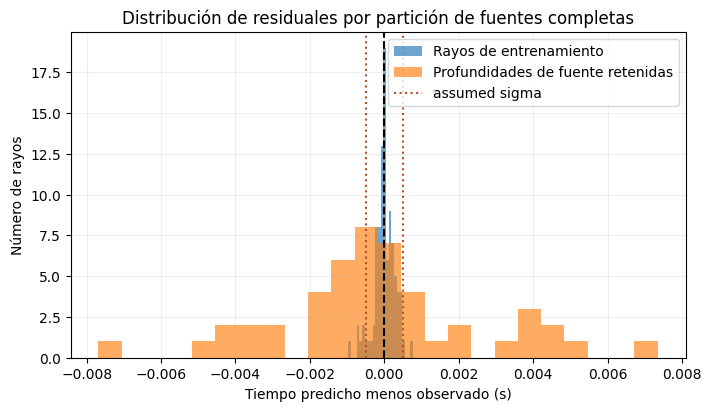

In [17]:
# Compare las distribuciones residuales sin usar los rayos retenidos para ajustar el modelo.
residual_train = pred[train] - t_obs[train]
residual_held = pred[held] - t_obs[held]
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
ax.hist(residual_train, bins=24, alpha=0.65, label="Rayos de entrenamiento")
ax.hist(residual_held, bins=24, alpha=0.65, label="Profundidades de fuente retenidas")
ax.axvline(0, color="black", ls="--")
ax.axvline(sigma_t, color="#b54f27", ls=":", label="assumed sigma")
ax.axvline(-sigma_t, color="#b54f27", ls=":")
ax.set(
    xlabel="Tiempo predicho menos observado (s)",
    ylabel="Número de rayos",
    title="Distribución de residuales por partición de fuentes completas",
)
ax.legend()
ax.grid(alpha=0.2)
plt.show()


### M10. Inversión acústica de forma de onda completa: cálculo real del producto

Este es un experimento M10 controlado e independiente del cálculo M09 de rayos rectos anterior. El producto modela presión acústica 2D de densidad constante con Deepwave, diferencia el objetivo de forma de onda y actualiza una velocidad acotada mediante L-BFGS con búsqueda de línea fuerte de Wolfe. Esquemáticamente, el término de datos es

$$\Phi_d(v)=rac{\|W(P(v)-d)_A\|_2^2}{\|Wd_A\|_2^2+\epsilon},\qquad \Phi(v)=\Phi_d(v)+eta R(v),$$

donde P(v) es la simulación de ondas por diferencias finitas del producto, d es el registro generado, A es el conjunto de receptores ajustados, W es el filtro de frecuencias declarado por el producto y R penaliza la rugosidad del gradiente de velocidad con escalas físicas. El experimento llama a `data-pipeline/seismic.py:solve_case`; no implementa un solver en el notebook ni lee una trayectoria guardada.

El caso fijo es `FWI_LAYERED`, semilla 4212, adquisición de referencia, fuente de 8 Hz y 40 receptores. El producto genera las observaciones con el mismo operador directo y ruido aditivo declarado. El modelo inicial es la tendencia de velocidad 1D independiente del producto. Antes de invertir se retienen los receptores cuyo índice módulo cinco es dos; esta partición intercalada comparte la apertura y no constituye un sondeo espacial independiente. Se ejecutan dos programas emparejados: banda completa y continuación en frecuencia del producto. Cada uno recibe una llamada al optimizador en cada una de las cuatro mallas de control; este presupuesto deliberadamente breve es diagnóstico, no una afirmación de convergencia. La verdad se usa solo después de invertir para calcular el RMSE del modelo.

#### Ejecutar la inversa real del producto

El producto requiere su `.venv-pipeline` con `requirements-gpu.txt` instalado. El kernel del notebook invoca ese entorno fijado y guarda el resultado temporal bajo `CAOS_TEMP_ROOT`; configure `CAOS_SOURCE_ROOT` solo si el entorno del motor está en otro checkout. La API del producto usa CUDA cuando está disponible; de lo contrario informa el dispositivo de ejecución documentado. Si falta el entorno del motor, el experimento falla explícitamente y no presenta un resultado sustituto.

In [18]:
# Call the product's Deepwave/PyTorch FWI inverse in its pinned pipeline environment.
import json
import os
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

root = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "data-pipeline" / "seismic.py").is_file())
engine_root = Path(os.environ.get("CAOS_SOURCE_ROOT", root))
engine = next((path for path in (engine_root / ".venv-pipeline" / "Scripts" / "python.exe", engine_root / ".venv-pipeline" / "bin" / "python") if path.is_file()), None)
if engine is None:
    raise RuntimeError("M10 needs the product .venv-pipeline with requirements-gpu.txt installed; set CAOS_SOURCE_ROOT to that environment's repository root.")
if "CAOS_TEMP_ROOT" not in os.environ:
    raise RuntimeError("Set CAOS_TEMP_ROOT to the device's external temporary-data root before running this experiment.")
result_path = Path(os.environ["CAOS_TEMP_ROOT"]) / "m10-fwi-layered-experiment.npz"
child = r"""
import json, sys
from pathlib import Path
import numpy as np
import torch
sys.path.insert(0, str(Path(sys.argv[1]) / "data-pipeline"))
import seismic

case = {"id": "FWI_LAYERED", "geometry": "layers", "seed": 4212}
variant = "reference"
iterations_per_stage = 1
run = seismic.solve_case(case, variant, iterations=iterations_per_stage)
initial = np.asarray(run["initial"], dtype=np.float32)
truth = np.asarray(run["truth"], dtype=np.float32)
observed = np.asarray(run["observed"], dtype=np.float32)
active = np.asarray(run["active_receivers"], dtype=bool)
device = run["methods"]["fwi-multiscale"]["device"]
with torch.no_grad():
    baseline_full = seismic.simulate(
        torch.as_tensor(initial.T, dtype=torch.float32, device=device),
        float(run["frequency"]), observed.shape[1], seismic.RECORD_SAMPLES,
    )
baseline = baseline_full[:, :, ::8].cpu().numpy()
sigma = float(run["parameters"]["noise_sigma"])
def wrms(prediction, receiver_mask):
    residual = prediction[:, receiver_mask] - observed[:, receiver_mask]
    return float(np.sqrt(np.mean(residual**2)) / sigma)
metrics = {
    "case": case,
    "variant": variant,
    "seed": int(case["seed"]),
    "engine": run["engine"],
    "device": device,
    "runtime_seconds_total": float(run["parameters"]["runtime_seconds"]),
    "grid": run["grid"],
    "frequency_hz": float(run["frequency"]),
    "noise_sigma": sigma,
    "receiver_split": run["parameters"]["withheld_policy"],
    "iterations_per_stage": iterations_per_stage,
    "optimizer_calls_per_schedule": iterations_per_stage * len(seismic.CONTROL_GRIDS),
    "baseline": {
        "active_wrms": wrms(baseline, active),
        "withheld_wrms": wrms(baseline, ~active),
        "velocity_rmse": float(np.sqrt(np.mean((initial-truth)**2))),
    },
    "methods": {},
}
models = {}
for key in ("fwi-l2", "fwi-multiscale"):
    method = run["methods"][key]
    metrics["methods"][key] = {
        **method["metrics"],
        "evaluation_status": method["evaluation"]["status"],
        "evaluation_reasons": method["evaluation"]["reason_codes"],
        "optimizer": method["solver"]["optimizer"],
        "terminal_state": method["solver"]["selected_state"],
    }
    models[key] = np.asarray(method["model"], dtype=np.float32)
np.savez_compressed(
    sys.argv[2], truth=truth, initial=initial,
    full_band=models["fwi-l2"], multiscale=models["fwi-multiscale"],
    metadata=json.dumps(metrics, sort_keys=True),
)
"""
completed = subprocess.run(
    [str(engine), "-c", child, str(root), str(result_path)],
    cwd=root, capture_output=True, text=True, timeout=3600, check=False,
)
if completed.returncode:
    raise RuntimeError("Product FWI process failed: " + completed.stderr[-6000:])
with np.load(result_path, allow_pickle=False) as result:
    truth = result["truth"]
    initial = result["initial"]
    full_band = result["full_band"]
    multiscale = result["multiscale"]
    fwi_metrics = json.loads(str(result["metadata"].item()))

print({key: fwi_metrics[key] for key in ("case", "variant", "seed", "engine", "device", "grid", "frequency_hz", "noise_sigma", "receiver_split", "iterations_per_stage", "optimizer_calls_per_schedule")})


{'case': {'geometry': 'layers', 'id': 'FWI_LAYERED', 'seed': 4212}, 'variant': 'reference', 'seed': 4212, 'engine': 'Deepwave 0.0.27 / PyTorch automatic differentiation', 'device': 'cuda', 'grid': {'shape': [96, 128], 'spacing': [12.5, 12.5]}, 'frequency_hz': 8.0, 'noise_sigma': 0.025693526268005373, 'receiver_split': 'receiver index modulo 5 equals 2, excluded from objectives and state selection', 'iterations_per_stage': 1, 'optimizer_calls_per_schedule': 4}


#### Puntuar el ajuste, los receptores retenidos y el error del modelo

WRMS divide la raíz del error cuadrático medio de forma de onda por la desviación estándar de ruido conocida del experimento. El ajuste y la retención usan las mismas máscaras de receptores para el modelo inicial y ambas inversas. El RMSE del modelo se calcula después de invertir frente a esta verdad sintética controlada; no está disponible para observaciones de campo. Se imprimen el estado de evaluación y los códigos de motivo del producto, sin convertir esta ejecución corta en un veredicto de aceptación del proyecto.

Los paneles comparten una escala física de color: verdad conocida, inicio independiente, resultado de banda completa y resultado de continuación en frecuencia. Compárelos con la tabla: un menor residual de forma de onda puede coexistir con una recuperación débil o sesgada del modelo. El puntaje retenido es solo un diagnóstico de receptores intercalados, no de generalización espacial.

,Method,Fit WRMS,Held-out WRMS,Model RMSE (m/s),RMSE / start
0,Independent 1-D start,50.235,50.145,229.095,1.000
1,"Product FWI, full band",13.820,13.720,220.564,0.963
2,"Product FWI, frequency continuation",15.285,15.162,220.474,0.962


Full band product evaluation: unresolved ['active_data_misfit_above_declared_noise', 'withheld_data_misfit_above_declared_noise']
Frequency continuation product evaluation: unresolved ['active_data_misfit_above_declared_noise', 'withheld_data_misfit_above_declared_noise']


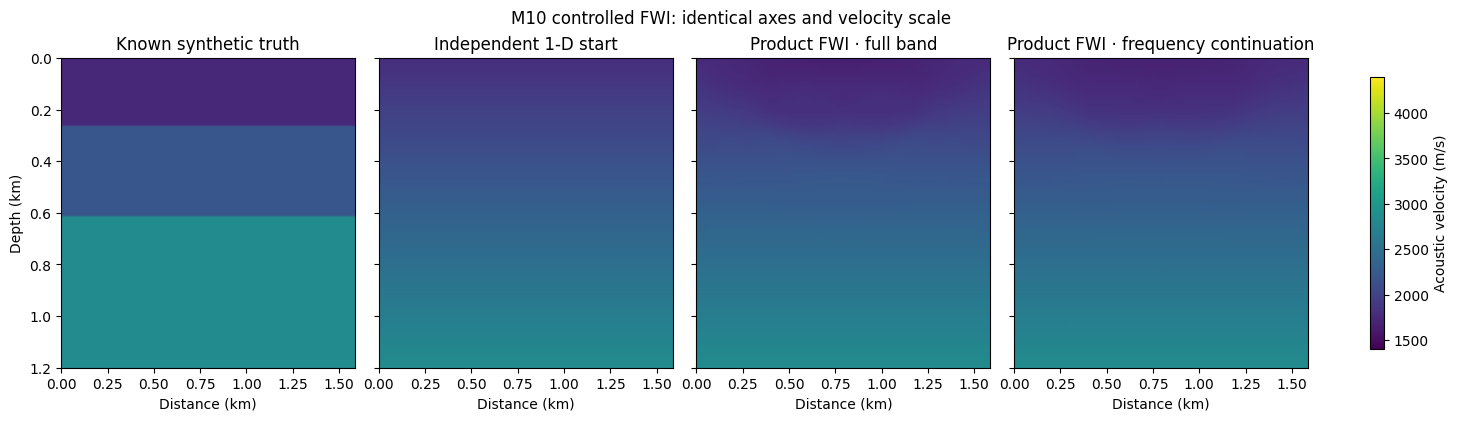

In [19]:
# Compare the product inverse with its declared independent start on identical receiver partitions.
rows = [{
    "Method": "Independent 1-D start",
    "Fit WRMS": fwi_metrics["baseline"]["active_wrms"],
    "Held-out WRMS": fwi_metrics["baseline"]["withheld_wrms"],
    "Model RMSE (m/s)": fwi_metrics["baseline"]["velocity_rmse"],
    "RMSE / start": 1.0,
}]
for key, label in (("fwi-l2", "Product FWI, full band"), ("fwi-multiscale", "Product FWI, frequency continuation")):
    metric = fwi_metrics["methods"][key]
    rows.append({
        "Method": label,
        "Fit WRMS": metric["active_wrms"],
        "Held-out WRMS": metric["withheld_wrms"],
        "Model RMSE (m/s)": metric["velocity_rmse"],
        "RMSE / start": metric["model_rmse_ratio"],
    })
score_table = pd.DataFrame(rows)
display(score_table.round(3))
for key, label in (("fwi-l2", "Full band"), ("fwi-multiscale", "Frequency continuation")):
    metric = fwi_metrics["methods"][key]
    print(label, "product evaluation:", metric["evaluation_status"], metric["evaluation_reasons"])

fig, axes = plt.subplots(1, 4, figsize=(14.5, 4.1), constrained_layout=True, sharex=True, sharey=True)
models = [truth, initial, full_band, multiscale]
titles = ["Known synthetic truth", "Independent 1-D start", "Product FWI · full band", "Product FWI · frequency continuation"]
images = []
for ax, model, title in zip(axes, models, titles):
    image = ax.imshow(model, origin="upper", aspect="auto", extent=[0, 127 * 12.5 / 1000, 96 * 12.5 / 1000, 0], cmap="viridis", vmin=1400, vmax=4400)
    images.append(image)
    ax.set(title=title, xlabel="Distance (km)")
axes[0].set_ylabel("Depth (km)")
fig.colorbar(images[-1], ax=axes, label="Acoustic velocity (m/s)", shrink=0.88)
fig.suptitle("M10 controlled FWI: identical axes and velocity scale")
plt.show()


**Limitaciones:** Los datos se generan con ruido sintético mediante el mismo motor numérico que usa la inversa; por tanto, no validan de forma independiente la física de ondas ni la transferencia a campo. El programa de solo cuatro llamadas por método puede dejar la optimización inconclusa. Persisten las hipótesis acústicas isotrópicas de densidad constante, firma de fuente conocida, adquisición fija, sensibilidad al modelo inicial, apertura finita y salto de ciclo. La partición retenida comparte la apertura del sondeo. Un mejor puntaje no demuestra geología correcta, recuperación única ni validez de campo.



## Resultados

**Respuesta:** La inversión de rayos rectos da WRMS retenido=5.591 en 48 rayos frente al objetivo unitario, por lo que los residuos superan el ruido supuesto. El RMSE de velocidad frente al modelo sintético conocido es 534.277 m/s.

### Control sintético M09 del producto

El cálculo suplementario LSQR de rayos rectos y el control pyGIMLi M09 del producto responden preguntas distintas. El segundo ejecuta el núcleo canónico de inversión Dijkstra con un modelo refractivo creado y de verdad conocida, informa predicción con grupos completos de fuentes retenidas y cobertura, y separa el error respecto de la verdad. Ningún resultado sintético demuestra que el caso de campo enlazado del proveedor sea elegible o científicamente aceptado.

## Resumen

Se retuvieron profundidades completas de fuente y aun así la predicción no es consistente con el ruido en esta geometría sintética. El resultado no valida el flujo de campo separado Koenigsee/pyGIMLi ni justifica interpretar velocidades de terreno.

## Referencias

- [Ejemplo pyGIMLi Koenigsee de primeras llegadas](https://www.pygimli.org/_examples_auto/2_seismics/plot_04_koenigsee/)
- [Marco de inversión pyGIMLi](https://www.pygimli.org/user-guide/inversion/)
- Parser, QC e inversa M09: data-pipeline/traveltime.py
- Experimento sintético generado en memoria, no datos de terreno.

**Respuesta:** La inversión de rayos rectos obtiene WRMS retenido=5,591 en 48 rayos frente al objetivo de ruido unitario 1,0; no es consistente con el ruido. El RMSE de velocidad respecto del modelo sintético conocido es 534,277 m/s.
